# E-commerce Product Recommendation System (Hybrid: CF + SVD + K-Means + Popularity)

**Goal:** recommend top-10 products for each user from implicit feedback (view / cart / remove_from_cart / purchase).

**Data:** `events`, `products`, `users`, `seller_offers` (real beauty-shop events from Dec 2019 + a **synthetic** segment of 800 demo users with a separate product catalog).

**Method overview**
1. Clean the data and run EDA (EDA is descriptive only - it does not feed the final model).
2. Time-based split: train < 20 Dec 2019, test >= 20 Dec; validation = 13-19 Dec (inside train).
3. Compare baselines (random / popularity), item-based CF, SVD, NMF on validation.
4. Build a hybrid (CF + SVD + cluster-popularity + popularity), tune K and weights on **validation only**.
5. Run the final test **once**, then a rolling backtest, export model + recommendations.

**Two evaluation modes (important)**
- `resurface`: only already-*purchased* items are removed from recommendations (easier, inflated - 42% of purchases were of items the user had already viewed/carted).
- `discovery`: every item the user already touched is removed (honest "new item" metric). **This is the primary metric of this project.**

## 0. Setup & configuration

In [35]:
import os, glob, json, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import statsmodels.api as sm
from scipy import stats
from scipy.stats import chi2_contingency
from scipy.sparse import csr_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.cluster import KMeans

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

# ---------------- CONFIG (only place with paths / constants) ----------------
# DATA_DIR: folder containing events.csv, products.csv, users.csv, seller_offers.csv
# Override with environment variable DATA_DIR if needed.
DATA_DIR = os.environ.get('DATA_DIR')
if DATA_DIR is None:
    hits = []
    for root in ['/kaggle/input', './data', '.']:
        hits += glob.glob(os.path.join(root, '**', 'events.csv'), recursive=True)
    if not hits:
        raise FileNotFoundError('events.csv not found. Set DATA_DIR to the folder that contains it.')
    DATA_DIR = os.path.dirname(min(hits, key=len))          # shortest path = main folder
OUT = os.environ.get('OUT_DIR',
                     '/kaggle/working/dashboard_export' if os.path.exists('/kaggle/working')
                     else './dashboard_export')
os.makedirs(OUT, exist_ok=True)

SYN_MIN    = 990000001                               # user_id >= this -> synthetic user
CUTOFF     = pd.Timestamp('2019-12-20', tz='UTC')    # train < CUTOFF <= test
VAL_CUT    = pd.Timestamp('2019-12-13', tz='UTC')    # train_core < VAL_CUT <= validation < CUTOFF
RATING_W   = {'view': 1, 'cart': 1.5, 'purchase': 2, 'remove_from_cart': 0}   # implicit rating weights
RATING_CAP = 2
W_POP      = {'view': 1, 'cart': 3, 'purchase': 5, 'remove_from_cart': 0}     # weights for cluster popularity
FINAL_W    = {'cf': .25, 'svd': .25, 'cl': .25, 'pop': .25}                   # hybrid weights
K_FINAL    = 8                                       # number of K-means clusters (see section 6.2)
print('DATA_DIR =', DATA_DIR); print('OUT      =', OUT)

DATA_DIR = /kaggle/input/datasets/nooriasafdar/recsys-dataa/recommendation_dataset/dataset
OUT      = /kaggle/working/dashboard_export


## 1. Load data

In [36]:
events   = pd.read_csv(f'{DATA_DIR}/events.csv', parse_dates=['event_time'])
products = pd.read_csv(f'{DATA_DIR}/products.csv')
users    = pd.read_csv(f'{DATA_DIR}/users.csv')
offers   = pd.read_csv(f'{DATA_DIR}/seller_offers.csv')

for name, d in [('events', events), ('products', products), ('users', users), ('offers', offers)]:
    print(f'{name:9s} {d.shape[0]:>7} rows, {d.shape[1]:>2} columns -> {list(d.columns)}')
events.head()

events      90244 rows,  6 columns -> ['event_time', 'event_type', 'user_id', 'product_id', 'user_session', 'source']
products     1885 rows, 10 columns -> ['product_id', 'product_name', 'brand', 'main_category', 'price', 'price_pkr', 'avg_rating', 'review_count', 'category_id', 'source']
users        3750 rows,  3 columns -> ['user_id', 'user_label', 'source']
offers       7451 rows, 12 columns -> ['product_id', 'seller_id', 'price', 'shipping', 'total_cost', 'price_pkr', 'shipping_pkr', 'total_cost_pkr', 'rating', 'review_count', 'stock', 'quality']


,event_time,event_type,user_id,product_id,user_session,source
0,2019-12-01 00:00:18+00:00,cart,579966747,5629988,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
1,2019-12-01 00:00:46+00:00,view,579966747,5798929,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
2,2019-12-01 00:01:55+00:00,view,990000531,9000117,syn-990000531-0,synthetic
3,2019-12-01 00:02:34+00:00,cart,579966747,5798924,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real
4,2019-12-01 00:02:41+00:00,view,579966747,5798929,1512be50-d0fd-4a92-bcd8-3ea3943f2a3b,real


In [37]:
events.info()
print(events.isna().sum())
print(events['event_type'].value_counts())
print(events['source'].value_counts())
display(events.describe(include='all').T)
display(products.describe(include='all').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90244 entries, 0 to 90243
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   event_time    90244 non-null  datetime64[ns, UTC]
 1   event_type    90244 non-null  object             
 2   user_id       90244 non-null  int64              
 3   product_id    90244 non-null  int64              
 4   user_session  90244 non-null  object             
 5   source        90244 non-null  object             
dtypes: datetime64[ns, UTC](1), int64(2), object(3)
memory usage: 4.1+ MB
event_time      0
event_type      0
user_id         0
product_id      0
user_session    0
source          0
dtype: int64
event_type
view                42754
cart                27056
remove_from_cart    12337
purchase             8097
Name: count, dtype: int64
source
real         70409
synthetic    19835
Name: count, dtype: int64


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
event_time,90244,NaN,NaN,NaN,2019-12-15 08:08:28.314203648+00:00,2019-12-01 00:00:18+00:00,2019-12-08 10:36:56.750000128+00:00,2019-12-14 19:03:07.500000+00:00,2019-12-22 12:37:27.249999872+00:00,2020-01-01 00:26:40+00:00,NaN
event_type,90244,4,view,42754,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,90244.0,NaN,NaN,NaN,625298289.565755,51824526.0,508907094.0,574720017.0,591948175.0,990000800.0,206131273.720533
product_id,90244.0,NaN,NaN,NaN,6107390.331834,3762.0,5739055.0,5820752.0,5894906.0,9000200.0,1954849.518054
user_session,90244,23175,ce626646-ab86-4478-a56d-5d7511e628da,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,90244,2,real,70409,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,1885.0,NaN,NaN,NaN,5750525.864191,1804648.797402,3762.0,5705014.0,5810672.0,5869143.0,9000200.0
product_name,1885,1853,Generic Beauty Product #4897,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,1885,113,unknown,775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
main_category,1885,10,Beauty & Salon Supplies,941,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,1885.0,NaN,NaN,NaN,12.054212,27.277822,0.08,1.98,4.21,7.78,385.3
price_pkr,1885.0,NaN,NaN,NaN,3375.184615,7637.796595,22.0,554.0,1179.0,2178.0,107884.0
avg_rating,1885.0,NaN,NaN,NaN,4.349019,0.205821,3.7,4.2,4.4,4.5,5.0
review_count,1885.0,NaN,NaN,NaN,804.467905,274.336367,126.0,613.0,784.0,973.0,1782.0
category_id,1685.0,NaN,NaN,NaN,1552928990427305984.0,174623739189266048.0,1487580004857414400.0,1487580005754995712.0,1487580008028308480.0,1487580012969197824.0,2235524494015856896.0
source,1885,2,real,1685,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Cleaning & merged table
`unknown` brand is treated as missing. Events are merged with product info and sorted by user and time.

In [38]:
products = products.drop(columns=['category_id'], errors='ignore')       # float-precision id, not needed
products['brand_clean'] = products['brand'].replace('unknown', np.nan)   # unknown = missing
products['is_branded']  = products['brand_clean'].notna()

events['event_time'] = pd.to_datetime(events['event_time'], utc=True)
df = events.merge(
    products[['product_id', 'product_name', 'brand', 'brand_clean', 'is_branded',
              'main_category', 'price', 'price_pkr']],
    on='product_id', how='left')

df['date']       = df['event_time'].dt.date
df['hour']       = df['event_time'].dt.hour
df['weekday']    = df['event_time'].dt.day_name()
df['is_weekend'] = df['event_time'].dt.dayofweek >= 5
df = df.sort_values(['user_id', 'event_time']).reset_index(drop=True)
print(df.shape, '| branded events: %.1f%%' % (df.is_branded.mean() * 100))
df.head()

(90244, 17) | branded events: 65.4%


,event_time,event_type,user_id,product_id,user_session,source,product_name,brand,brand_clean,is_branded,main_category,price,price_pkr,date,hour,weekday,is_weekend
0,2019-12-03 05:57:04+00:00,view,51824526,5650457,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Metzger Beauty Product #0457,metzger,metzger,True,Beauty & Salon Supplies,6.83,1912,2019-12-03,5,Tuesday,False
1,2019-12-03 05:58:30+00:00,view,51824526,5650457,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Metzger Beauty Product #0457,metzger,metzger,True,Beauty & Salon Supplies,6.83,1912,2019-12-03,5,Tuesday,False
2,2019-12-03 06:07:45+00:00,view,51824526,5885848,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Generic Beauty Product #5848,unknown,NaN,False,Beauty & Salon Supplies,7.22,2022,2019-12-03,6,Tuesday,False
3,2019-12-03 06:08:31+00:00,view,51824526,5650457,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Metzger Beauty Product #0457,metzger,metzger,True,Beauty & Salon Supplies,6.83,1912,2019-12-03,6,Tuesday,False
4,2019-12-03 06:25:33+00:00,cart,51824526,5650457,c24778fb-fb85-40f9-910b-0c15896bc58c,real,Metzger Beauty Product #0457,metzger,metzger,True,Beauty & Salon Supplies,6.83,1912,2019-12-03,6,Tuesday,False


In [39]:
# data quality checks
print(df.isna().sum())
print('Duplicates:', df.duplicated().sum())
print('Price <= 0:', (df['price'] <= 0).sum())
print('Invalid event types:', (~df['event_type'].isin(['view', 'cart', 'remove_from_cart', 'purchase'])).sum())
print('Time range:', df['event_time'].min(), '->', df['event_time'].max())
print('Synthetic ID mismatch:', ((df['source'] == 'synthetic') != (df['user_id'] >= SYN_MIN)).sum())
assert df['product_name'].notna().all(), 'some events have no matching product'

event_time           0
event_type           0
user_id              0
product_id           0
user_session         0
source               0
product_name         0
brand                0
brand_clean      31237
is_branded           0
main_category        0
price                0
price_pkr            0
date                 0
hour                 0
weekday              0
is_weekend           0
dtype: int64
Duplicates: 0
Price <= 0: 0
Invalid event types: 0
Time range: 2019-12-01 00:00:18+00:00 -> 2020-01-01 00:26:40+00:00
Synthetic ID mismatch: 0


## 3. Exploratory data analysis & statistical checks
> **EDA only.** This section describes the data (it uses all dates). Nothing here feeds the final model.

IQR upper limit: 56.5 | users above it: 302 | max events: 300
Heavy users are kept (they are real behaviour, not errors).


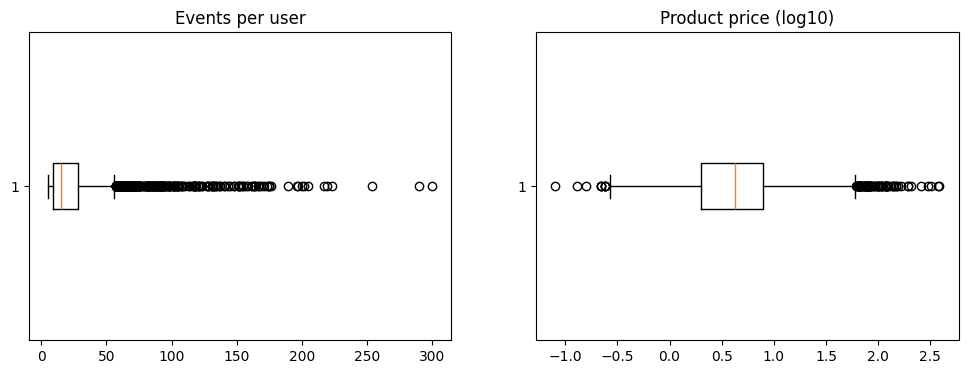

In [40]:
# 3.1 outliers: events per user and product price
user_ev = df.groupby('user_id').size()
q1, q3 = user_ev.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print('IQR upper limit:', upper, '| users above it:', (user_ev > upper).sum(), '| max events:', user_ev.max())
print('Heavy users are kept (they are real behaviour, not errors).')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot(user_ev, vert=False); ax[0].set_title('Events per user')
ax[1].boxplot(np.log10(products['price']), vert=False); ax[1].set_title('Product price (log10)')
plt.show()

           feature  skew  kurtosis     shapiro_p
0             view  3.74     23.09  4.796704e-65
1             cart  4.22     27.83  1.880138e-67
2         purchase  3.60     22.68  1.049463e-67
3     total_events  3.57     18.61  9.844924e-67
4  unique_products  2.97     14.10  6.170213e-61
5        avg_price  2.55      8.22  5.325454e-66


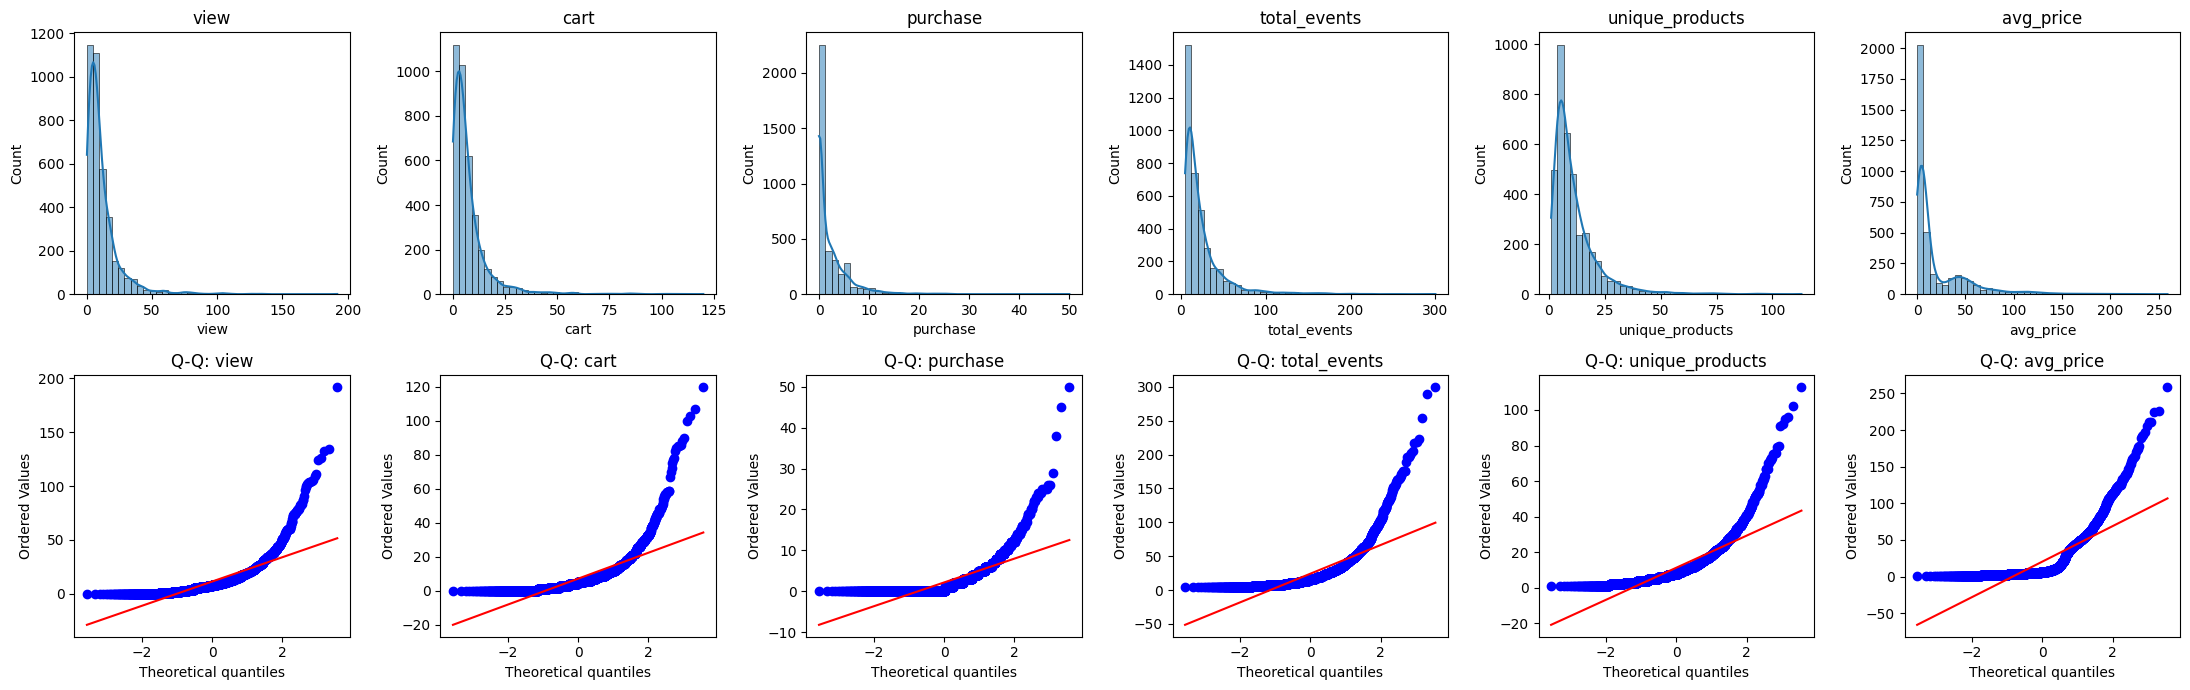

In [41]:
# 3.2 per-user summary table + distribution shape
ue = df.pivot_table(index='user_id', columns='event_type', values='product_id',
                    aggfunc='count', fill_value=0)
ue['total_events']    = ue.sum(axis=1)
ue['unique_products'] = df.groupby('user_id')['product_id'].nunique()
ue['avg_price']       = df.groupby('user_id')['price'].mean()
ue['source']          = df.groupby('user_id')['source'].first()
num = ['view', 'cart', 'purchase', 'total_events', 'unique_products', 'avg_price']

rows = []
for c in num:
    x = ue[c]
    s = x.sample(min(5000, len(x)), random_state=42)
    rows.append([c, round(x.skew(), 2), round(stats.kurtosis(x), 2), stats.shapiro(s)[1]])
print(pd.DataFrame(rows, columns=['feature', 'skew', 'kurtosis', 'shapiro_p']))

fig, ax = plt.subplots(2, 6, figsize=(22, 7))
for i, c in enumerate(num):
    sns.histplot(ue[c], bins=40, kde=True, ax=ax[0, i]); ax[0, i].set_title(c)
    stats.probplot(ue[c], dist='norm', plot=ax[1, i]); ax[1, i].set_title(f'Q-Q: {c}')
plt.tight_layout(); plt.show()

                 before  after_log
event_type                        
view               3.74      -0.22
cart               4.22      -0.03
purchase           3.60       0.78
total_events       3.57       0.68
unique_products    2.97       0.20
avg_price          2.55       0.67


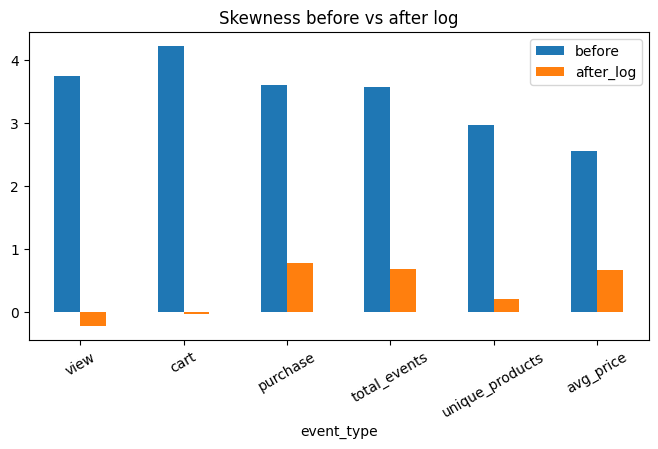

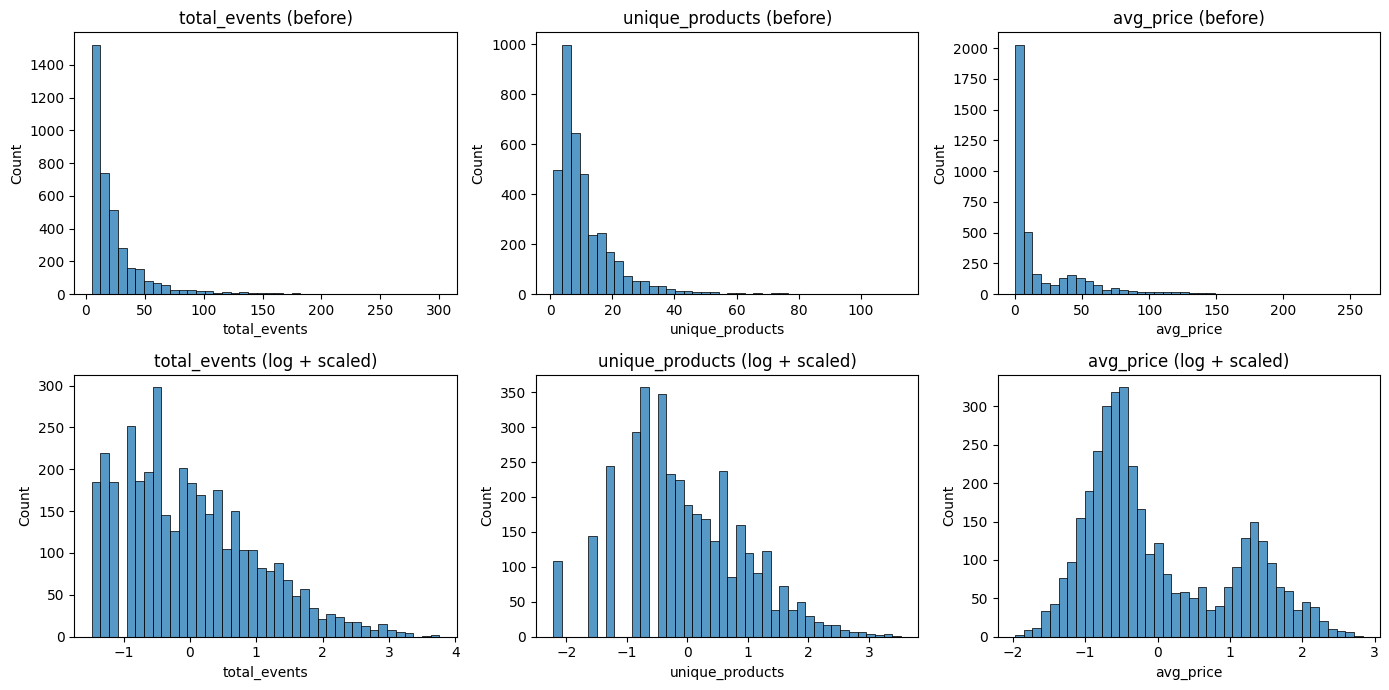

      view  cart  purchase  total_events  unique_products  avg_price
mean   0.0   0.0       0.0          -0.0             -0.0        0.0
std    1.0   1.0       1.0           1.0              1.0        1.0


In [42]:
# 3.3 normalisation: log1p + standardisation
X = ue[num].copy()
X_log = np.log1p(X)
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X_log), columns=num, index=X.index)

skew = pd.DataFrame({'before': X.skew(), 'after_log': X_log.skew()}).round(2)
print(skew)
skew.plot(kind='bar', figsize=(8, 4), title='Skewness before vs after log'); plt.xticks(rotation=30); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, c in enumerate(['total_events', 'unique_products', 'avg_price']):
    sns.histplot(X[c], bins=40, ax=ax[0, i]); ax[0, i].set_title(f'{c} (before)')
    sns.histplot(X_scaled[c], bins=40, ax=ax[1, i]); ax[1, i].set_title(f'{c} (log + scaled)')
plt.tight_layout(); plt.show()
print(X_scaled.describe().loc[['mean', 'std']].round(2))

                          pair    chi2  p_value  cramers_v
0  main_category vs event_type  3909.2      0.0      0.120
1         source vs event_type  4267.1      0.0      0.217


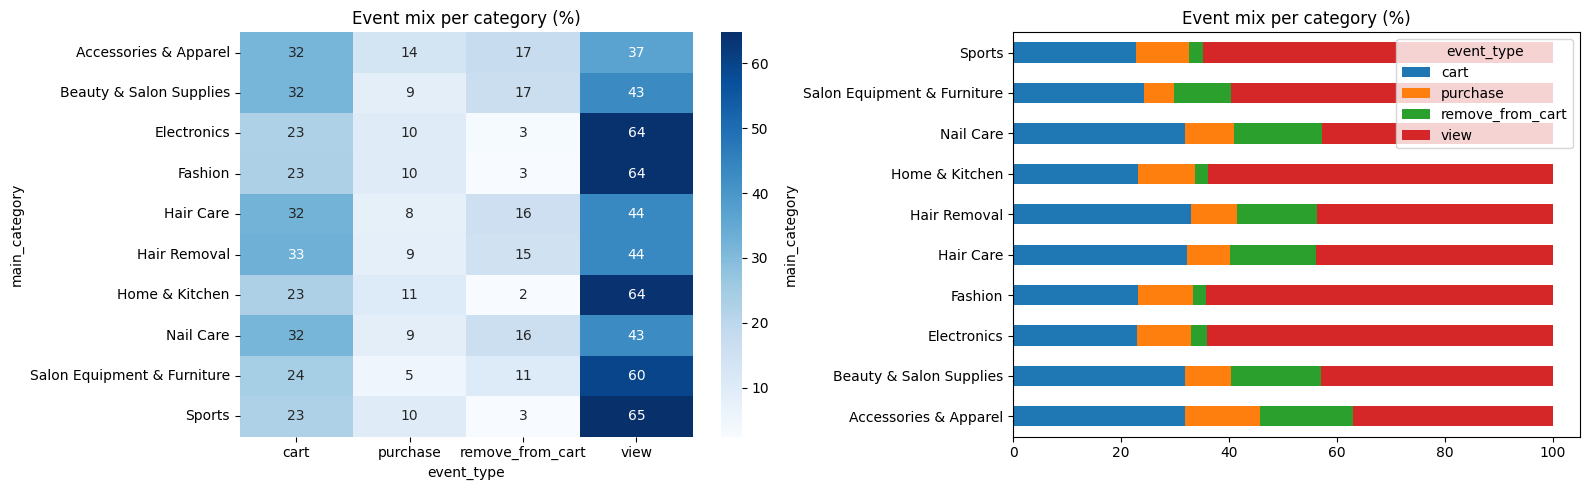

In [43]:
# 3.4 association: chi-square + Cramer's V
# (note: events of the same user are not independent, so p-values are only indicative; use Cramer's V as effect size)
def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

res = []
for a, b in [('main_category', 'event_type'), ('source', 'event_type')]:
    ct = pd.crosstab(df[a], df[b])
    chi2, p, dof, _ = chi2_contingency(ct)
    res.append([f'{a} vs {b}', round(chi2, 1), p, round(cramers_v(ct), 3)])
print(pd.DataFrame(res, columns=['pair', 'chi2', 'p_value', 'cramers_v']))

ct = pd.crosstab(df['main_category'], df['event_type'])
pct = ct.div(ct.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(pct, annot=True, fmt='.0f', cmap='Blues', ax=ax[0]); ax[0].set_title('Event mix per category (%)')
pct.plot(kind='barh', stacked=True, ax=ax[1], title='Event mix per category (%)')
plt.tight_layout(); plt.show()

           feature    VIF
0             view   3.79
1             cart   4.14
2         purchase   1.61
3     total_events  11.26
4  unique_products   3.59
5        avg_price   1.28
total_events is the sum of the other counts -> expected high VIF; drop it.
           feature   VIF
0             view  1.86
1             cart  2.05
2         purchase  1.44
3  unique_products  2.60
4        avg_price  1.20


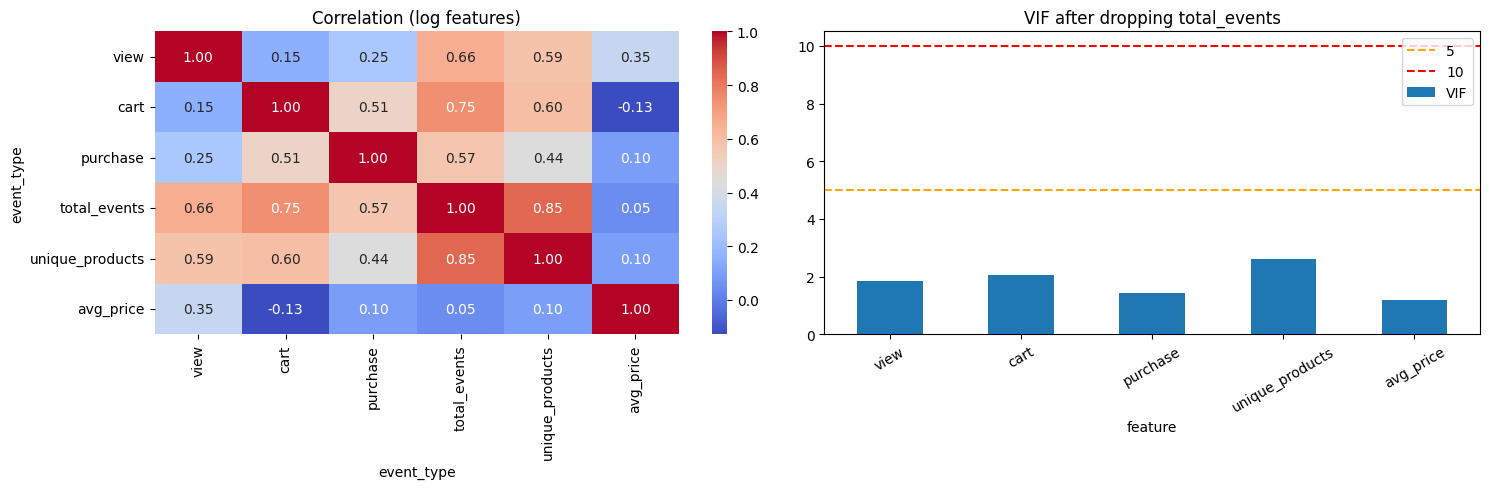

In [44]:
# 3.5 multicollinearity (VIF)
Xv = sm.add_constant(X_log)
vif = pd.DataFrame({'feature': X_log.columns,
                    'VIF': [variance_inflation_factor(Xv.values, i + 1) for i in range(X_log.shape[1])]})
print(vif.round(2))
print('total_events is the sum of the other counts -> expected high VIF; drop it.')

feat = ['view', 'cart', 'purchase', 'unique_products', 'avg_price']
Xv2 = sm.add_constant(X_log[feat])
vif2 = pd.DataFrame({'feature': feat,
                     'VIF': [variance_inflation_factor(Xv2.values, i + 1) for i in range(len(feat))]})
print(vif2.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(X_log.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax[0]); ax[0].set_title('Correlation (log features)')
vif2.set_index('feature')['VIF'].plot(kind='bar', ax=ax[1], title='VIF after dropping total_events')
ax[1].axhline(5, color='orange', ls='--', label='5'); ax[1].axhline(10, color='red', ls='--', label='10')
ax[1].legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

Mean  real/syn: 23.9 24.8
Var   real/syn: 821.9 244.8
Levene (variance): LeveneResult(statistic=np.float64(19.834956018957676), pvalue=np.float64(8.688629004030724e-06))
Welch t-test (mean): TtestResult(statistic=np.float64(-1.2114641665945391), pvalue=np.float64(0.22583776325608693), df=np.float64(2381.293935951988))
Mann-Whitney (distribution): MannwhitneyuResult(statistic=np.float64(861426.5), pvalue=np.float64(8.204879956068655e-32))
-> Means are similar, but the distributions differ (Mann-Whitney) - synthetic users are more uniform.
ANOVA (price by category): F_onewayResult(statistic=np.float64(113.0141411946541), pvalue=np.float64(2.0036429439123125e-169))
Kruskal-Wallis: KruskalResult(statistic=np.float64(529.7750343298524), pvalue=np.float64(2.4079003744420005e-108))
Views buyer/non-buyer: 14.2 8.6 MannwhitneyuResult(statistic=np.float64(2212516.5), pvalue=np.float64(5.489891583494744e-43))


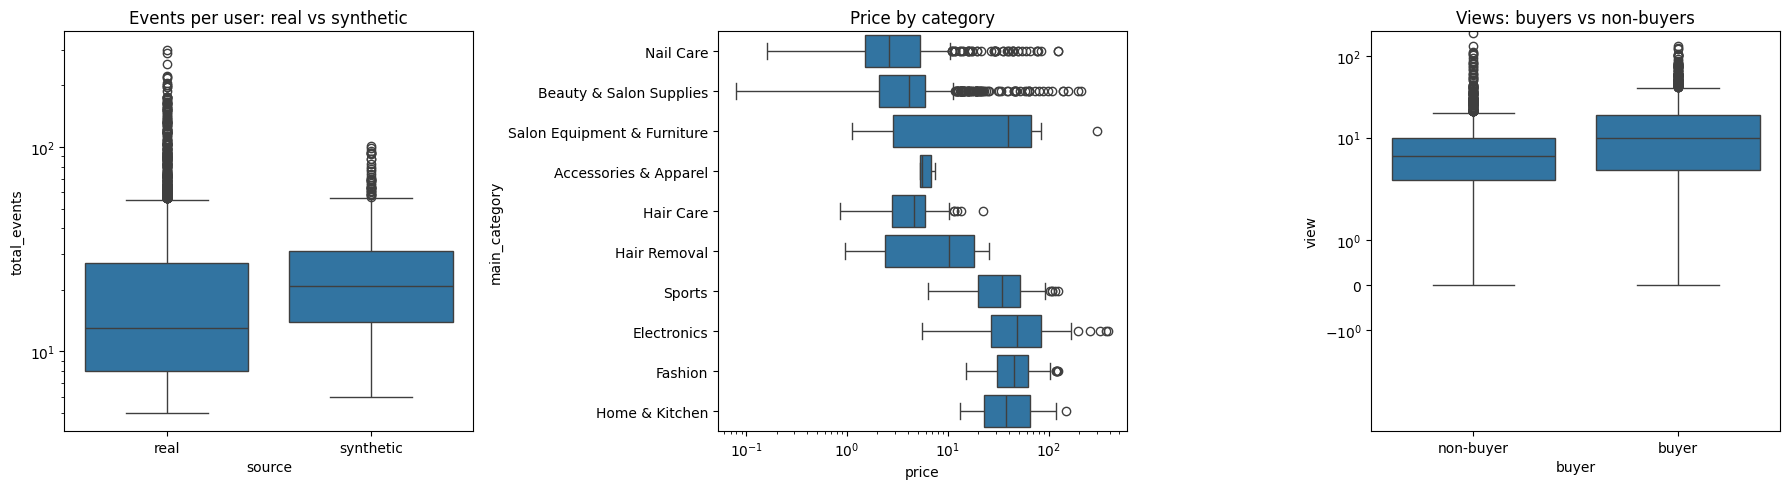

In [45]:
# 3.6 group comparisons (parametric AND non-parametric, because the data is heavily skewed)
real = ue[ue.source == 'real']['total_events']
syn  = ue[ue.source == 'synthetic']['total_events']
print('Mean  real/syn:', round(real.mean(), 1), round(syn.mean(), 1))
print('Var   real/syn:', round(real.var(), 1), round(syn.var(), 1))
print('Levene (variance):', stats.levene(real, syn))
print('Welch t-test (mean):', stats.ttest_ind(real, syn, equal_var=False))
print('Mann-Whitney (distribution):', stats.mannwhitneyu(real, syn))
print('-> Means are similar, but the distributions differ (Mann-Whitney) - synthetic users are more uniform.')

groups = [g['price'].values for _, g in products.groupby('main_category')]
print('ANOVA (price by category):', stats.f_oneway(*groups))
print('Kruskal-Wallis:', stats.kruskal(*groups))

ue['buyer'] = np.where(ue['purchase'] > 0, 'buyer', 'non-buyer')
buy, nobuy = ue[ue.buyer == 'buyer']['view'], ue[ue.buyer == 'non-buyer']['view']
print('Views buyer/non-buyer:', round(buy.mean(), 1), round(nobuy.mean(), 1), stats.mannwhitneyu(buy, nobuy))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=ue, x='source', y='total_events', ax=ax[0]); ax[0].set_yscale('log'); ax[0].set_title('Events per user: real vs synthetic')
sns.boxplot(data=products, y='main_category', x='price', ax=ax[1]); ax[1].set_xscale('log'); ax[1].set_title('Price by category')
sns.boxplot(data=ue, x='buyer', y='view', ax=ax[2]); ax[2].set_yscale('symlog'); ax[2].set_title('Views: buyers vs non-buyers')
plt.tight_layout(); plt.show()

## 4. Train / validation / test split and rating matrix

```
1 Dec ------------ 13 Dec ------------ 20 Dec ------------ 1 Jan
   train_core          validation              test
   |<----------- train_t ---------->|
```
- Test pairs = purchases after the cutoff of items the user had **not purchased before**.
- `is_warm` = the user already has history before the cutoff; cold users get popularity.

In [46]:
train_t = df[df.event_time < CUTOFF].copy()
after   = df[df.event_time >= CUTOFF]

def make_pairs(train_df, later_df):
    """Purchases in later_df of items the user had not purchased in train_df."""
    bought = (train_df[train_df.event_type == 'purchase'][['user_id', 'product_id']]
              .drop_duplicates().assign(seen=1))
    p = (later_df[later_df.event_type == 'purchase'][['user_id', 'product_id']]
         .drop_duplicates()
         .merge(bought, on=['user_id', 'product_id'], how='left'))
    p = p[p.seen.isna()].drop(columns='seen')
    p['is_warm'] = p.user_id.isin(set(train_df.user_id))      # True = user has history in train
    p['source']  = np.where(p.user_id >= SYN_MIN, 'synthetic', 'real')
    return p

# final test pairs (used ONCE in section 7)
test_t = make_pairs(train_t, after)
print('Train rows:', len(train_t), '| Test pairs:', len(test_t))
print(test_t.groupby(['source', 'is_warm']).user_id.nunique())

# validation split inside train
train_core = train_t[train_t.event_time <  VAL_CUT].copy()   # 1-12 Dec
val_period = train_t[train_t.event_time >= VAL_CUT].copy()   # 13-19 Dec
val_pairs  = make_pairs(train_core, val_period)

# leakage checks
assert train_core.event_time.max() < val_period.event_time.min()
assert train_t.event_time.max() < CUTOFF
print('train_core :', len(train_core), 'rows |', train_core.event_time.min().date(), '->', train_core.event_time.max().date())
print('val_period :', len(val_period), 'rows |', val_period.event_time.min().date(), '->', val_period.event_time.max().date())
print('val_pairs  :', len(val_pairs))
print(val_pairs.groupby(['source', 'is_warm']).user_id.nunique())

Train rows: 61041 | Test pairs: 2570
source     is_warm
real       False      234
           True       167
synthetic  True       456
Name: user_id, dtype: int64
train_core : 40468 rows | 2019-12-01 -> 2019-12-12
val_period : 20573 rows | 2019-12-13 -> 2019-12-19
val_pairs  : 1862
source     is_warm
real       False      162
           True       160
synthetic  False        2
           True       287
Name: user_id, dtype: int64


In [47]:
# implicit ratings: there are no explicit ratings, so events are converted to numbers
item_ids = np.sort(products['product_id'].unique())
i_idx    = {p: i for i, p in enumerate(item_ids)}

def build_R(train_df, w=None, cap=None, real_only=False):
    """User x item rating matrix from any training data. real_only=True drops synthetic users."""
    w   = RATING_W if w is None else w
    cap = RATING_CAP if cap is None else cap
    t = train_df[train_df.user_id < SYN_MIN].copy() if real_only else train_df.copy()
    t['w'] = t['event_type'].map(w)
    r = t.groupby(['user_id', 'product_id'])['w'].sum().reset_index()
    r = r[r['w'] > 0]
    r['rating'] = r['w'].clip(upper=cap)
    uids = np.sort(r['user_id'].unique())
    uix  = {u: i for i, u in enumerate(uids)}
    M = csr_matrix((r['rating'].values,
                    (r['user_id'].map(uix).values, r['product_id'].map(i_idx).values)),
                   shape=(len(uids), len(item_ids)))
    return M, uids, uix

R, user_ids, u_idx = build_R(train_t)
print('Matrix shape:', R.shape)
print('Filled cells:', R.nnz, '| Sparsity:', round(1 - R.nnz / (R.shape[0] * R.shape[1]), 4))

R_core, uids_core, uix_core = build_R(train_core)
R_core_real, uids_core_real, uix_core_real = build_R(train_core, real_only=True)
print('R_core (all users):', R_core.shape, '| R_core (real only):', R_core_real.shape)
print('Note: purchase = 2, view+cart = 2.5 -> clipped to 2, so purchase and view+cart get the same rating (known simplification).')

Matrix shape: (3085, 1885)
Filled cells: 27980 | Sparsity: 0.9952
R_core (all users): (2509, 1885) | R_core (real only): (1716, 1885)
Note: purchase = 2, view+cart = 2.5 -> clipped to 2, so purchase and view+cart get the same rating (known simplification).


## 5. Evaluation helpers

In [48]:
def popularity_scores(train_df, days=None, w=None, real_only=False):
    """Popularity points per product. days=7 -> only the last 7 days of train_df."""
    w = RATING_W if w is None else w
    d = train_df[train_df.user_id < SYN_MIN] if real_only else train_df
    if days is not None:
        d = d[d.event_time >= d.event_time.max() - pd.Timedelta(days=days)]
    s = d['event_type'].map(w).groupby(d['product_id']).sum()
    return s.reindex(item_ids).fillna(0).values.astype(float)

def topk(s, k=10):
    idx = np.argpartition(-s, k)[:k]
    return idx[np.argsort(-s[idx])]

def evaluate_mode(score_fn, train_df, uix, pairs, k=10, mode='discovery', source='real'):
    """score_fn(user_id) -> score for every product.
    mode='resurface': only purchased items are removed.
    mode='discovery': viewed / carted / removed / purchased items are all removed (honest metric)."""
    p = pairs[(pairs.source == source) & (pairs.is_warm) & (pairs.user_id.isin(uix))]
    src = train_df if mode == 'discovery' else train_df[train_df.event_type == 'purchase']
    seen = src.groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
    disc = 1 / np.log2(np.arange(2, k + 2))
    out = []
    for u, g in p.groupby('user_id'):
        s = np.asarray(score_fn(u), dtype=float).copy()
        b = seen.get(u)
        if b is not None:
            s[b] = -np.inf
        rec   = topk(s, k)
        truth = set(g['product_id'].map(i_idx))
        hit   = np.array([r in truth for r in rec])
        ideal = disc[:min(len(truth), k)].sum()
        out.append((u, int(hit.any()), hit.sum() / k, (hit * disc).sum() / ideal))
    return pd.DataFrame(out, columns=['user_id', 'hit', 'precision', 'ndcg'])

def evaluate(score_fn, train_df, uix, pairs, k=10):           # resurface mode (inflated)
    return evaluate_mode(score_fn, train_df, uix, pairs, k, mode='resurface')

def evaluate_cold(score_vec, pairs, k=10):
    """Users with NO history before the cut: everybody gets the same top-k."""
    p = pairs[(pairs.source == 'real') & (~pairs.is_warm)]
    rec = topk(np.asarray(score_vec, dtype=float), k)
    disc = 1 / np.log2(np.arange(2, k + 2))
    out = []
    for u, g in p.groupby('user_id'):
        truth = set(g['product_id'].map(i_idx))
        hit = np.array([r in truth for r in rec])
        ideal = disc[:min(len(truth), k)].sum()
        out.append((u, int(hit.any()), hit.sum() / k, (hit * disc).sum() / ideal))
    return pd.DataFrame(out, columns=['user_id', 'hit', 'precision', 'ndcg'])

def summarize(res, name, n_boot=2000, seed=42):
    """hit@10 with 95% bootstrap CI, precision@10, ndcg@10."""
    rng = np.random.default_rng(seed)
    x = res['hit'].values
    means = rng.choice(x, (n_boot, len(x))).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return {'model': name, 'users': len(res),
            'hit@10': round(x.mean(), 3), 'ci_lo': round(lo, 3), 'ci_hi': round(hi, 3),
            'precision@10': round(res['precision'].mean(), 3),
            'ndcg@10': round(res['ndcg'].mean(), 3)}

def paired_diff(a, b, col, n_boot=2000, seed=42):
    """Mean difference a-b per user with 95% bootstrap CI."""
    m = a.merge(b, on='user_id', suffixes=('_a', '_b'))
    d = (m[col + '_a'] - m[col + '_b']).values
    means = np.random.default_rng(seed).choice(d, (n_boot, len(d))).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return round(d.mean(), 3), round(lo, 3), round(hi, 3)

def verdict(lo, hi):
    return 'real difference' if (lo > 0 or hi < 0) else 'not significant (CI includes 0)'

## 6. Baselines, CF, SVD and NMF (validation)
Everything in sections 6-7 is judged on the **validation** period (13-19 Dec). The test period is not touched until section 8.

In [49]:
# 6.1 baselines
pop_core_all      = popularity_scores(train_core)
pop_core_7        = popularity_scores(train_core, days=7)
pop_core_all_real = popularity_scores(train_core, real_only=True)
pop_core_7_real   = popularity_scores(train_core, days=7, real_only=True)
pop_n = pop_core_7_real / (pop_core_7_real.max() + 1e-9)          # normalised popularity (used in blends)
rng_rand = np.random.default_rng(42)

baselines = {
    'Random':                     lambda u: rng_rand.random(len(item_ids)),
    'Popularity (all)':           lambda u: pop_core_all,
    'Popularity (last 7d)':       lambda u: pop_core_7,
    'Popularity real-only (all)': lambda u: pop_core_all_real,
    'Popularity real-only (7d)':  lambda u: pop_core_7_real,
}
rows = [summarize(evaluate(fn, train_core, uix_core, val_pairs), name) for name, fn in baselines.items()]
val_results = pd.DataFrame(rows)
display(val_results)

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,Random,159,0.038,0.013,0.069,0.004,0.005
1,Popularity (all),159,0.164,0.107,0.220,0.020,0.042
2,Popularity (last 7d),159,0.170,0.113,0.226,0.018,0.042
3,Popularity real-only (all),159,0.214,0.151,0.277,0.029,0.055
4,Popularity real-only (7d),159,0.214,0.151,0.277,0.029,0.055


In [50]:
# 6.2 item-based CF, SVD, NMF - "resurface" mode (inflated, see warning below)
tie = 1e-6 * (pop_core_all_real / (pop_core_all_real.max() + 1e-9))      # break ties by popularity

def make_cf(Rm, uix):
    S = cosine_similarity(Rm.T, dense_output=False).toarray()
    np.fill_diagonal(S, 0)
    return lambda u: np.asarray(Rm[uix[u]] @ S).ravel() + tie

def make_svd(Rm, uix, n):
    m = TruncatedSVD(n_components=n, random_state=42)
    U = m.fit_transform(Rm); V = m.components_
    return lambda u: U[uix[u]] @ V + tie

def make_nmf(Rm, uix, n):
    m = NMF(n_components=n, init='nndsvda', max_iter=300, random_state=42)
    W = m.fit_transform(Rm); H = m.components_
    return lambda u: W[uix[u]] @ H + tie

variants = {'all users': (R_core, uix_core), 'real only': (R_core_real, uix_core_real)}
rows = []
for tag, (Rm, uix) in variants.items():
    rows.append(summarize(evaluate(make_cf(Rm, uix), train_core, uix, val_pairs), f'CF ({tag})'))
    for n in [10, 20, 50, 100, 200]:
        if n < min(Rm.shape):
            rows.append(summarize(evaluate(make_svd(Rm, uix, n), train_core, uix, val_pairs), f'SVD n={n} ({tag})'))
    for n in [10, 20, 50, 100]:
        if n < min(Rm.shape):
            rows.append(summarize(evaluate(make_nmf(Rm, uix, n), train_core, uix, val_pairs), f'NMF n={n} ({tag})'))
mf_results = pd.DataFrame(rows)
display(pd.concat([val_results, mf_results], ignore_index=True).sort_values('ndcg@10', ascending=False).reset_index(drop=True))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,SVD n=200 (real only),159,0.635,0.560,0.711,0.158,0.309
1,SVD n=200 (all users),159,0.623,0.547,0.698,0.149,0.287
2,SVD n=100 (real only),159,0.572,0.497,0.648,0.128,0.251
3,SVD n=100 (all users),159,0.579,0.503,0.654,0.125,0.235
4,CF (real only),159,0.497,0.421,0.572,0.121,0.209
5,CF (all users),159,0.509,0.434,0.585,0.119,0.207
6,NMF n=100 (real only),159,0.516,0.440,0.597,0.097,0.185
7,SVD n=50 (real only),159,0.491,0.415,0.566,0.093,0.183
8,SVD n=50 (all users),159,0.522,0.447,0.604,0.095,0.182
9,NMF n=100 (all users),159,0.528,0.447,0.610,0.092,0.181


> **Warning - do not read these numbers as final.** In `resurface` mode large SVD (n=200) looks best because it mostly re-recommends items the user already viewed/carted. The next cell shows the honest `discovery` view, where the ranking changes.

In [51]:
# 6.3 honest check: resurface vs discovery for the same models
pp = val_pairs[(val_pairs.source == 'real') & val_pairs.is_warm & val_pairs.user_id.isin(uix_core_real)]
touched = train_core.groupby('user_id')['product_id'].apply(set)
share_touched = np.mean([pid in touched.get(u, set()) for u, pid in zip(pp.user_id, pp.product_id)])
print(f'Validation purchases that were already viewed/carted before: {share_touched:.1%}')

def blend(fn, w=0.5):
    def f(u):
        s = np.clip(np.asarray(fn(u), dtype=float), 0, None)
        return (1 - w) * s / (s.max() + 1e-9) + w * pop_n
    return f

Rm, uix = R_core_real, uix_core_real
models = {'Popularity (7d, real)': (lambda u: pop_core_7_real),
          'CF (real only)': make_cf(Rm, uix)}
for n in (10, 20, 50, 100, 200):
    if n < min(Rm.shape):
        models[f'SVD n={n}'] = make_svd(Rm, uix, n)
for n in (50, 100):
    if n < min(Rm.shape):
        models[f'NMF n={n}'] = make_nmf(Rm, uix, n)
models['CF + popularity'] = blend(models['CF (real only)'])
if 'SVD n=50' in models:
    models['SVD n=50 + popularity'] = blend(models['SVD n=50'])

rows = []
for name, fn in models.items():
    a = summarize(evaluate_mode(fn, train_core, uix, val_pairs, mode='resurface'), name)
    b = summarize(evaluate_mode(fn, train_core, uix, val_pairs, mode='discovery'), name)
    rows.append((name, a['hit@10'], b['hit@10'], b['ci_lo'], b['ci_hi'], a['ndcg@10'], b['ndcg@10']))
honest = pd.DataFrame(rows, columns=['model', 'hit_resurface', 'hit_DISCOVERY', 'disc_ci_lo', 'disc_ci_hi',
                                     'ndcg_resurface', 'ndcg_DISCOVERY'])
display(honest.sort_values('ndcg_DISCOVERY', ascending=False).reset_index(drop=True))

Validation purchases that were already viewed/carted before: 42.1%


,model,hit_resurface,hit_DISCOVERY,disc_ci_lo,disc_ci_hi,ndcg_resurface,ndcg_DISCOVERY
0,SVD n=50,0.491,0.107,0.057,0.157,0.183,0.027
1,SVD n=20,0.409,0.119,0.069,0.170,0.127,0.025
2,NMF n=50,0.440,0.101,0.057,0.151,0.153,0.025
3,SVD n=50 + popularity,0.447,0.132,0.082,0.189,0.144,0.024
4,CF + popularity,0.522,0.132,0.082,0.182,0.180,0.022
5,SVD n=100,0.572,0.075,0.038,0.119,0.251,0.022
6,NMF n=100,0.516,0.082,0.044,0.126,0.185,0.021
7,CF (real only),0.497,0.094,0.050,0.138,0.209,0.018
8,"Popularity (7d, real)",0.214,0.101,0.057,0.145,0.055,0.016
9,SVD n=10,0.302,0.094,0.050,0.145,0.092,0.016


## 7. Hybrid model and tuning (validation only)
The hybrid mixes four normalised scores: item-based **CF**, **SVD (n=50)**, **cluster popularity** (K-means on SVD user embeddings, 30% blended with global popularity) and global **popularity (7 days)**.

In [52]:
# 7.1 cluster-popularity component and hybrid variants (judged on NEW items only)
Rm, uix = R_core_real, uix_core_real
Xe = normalize(TruncatedSVD(n_components=16, random_state=42).fit_transform(Rm))   # user embeddings
tr_r = train_core[train_core.user_id.isin(uix)]
w_  = tr_r.event_type.map(W_POP).values
ip_ = tr_r.product_id.map(i_idx).values.astype(int)
ur_ = tr_r.user_id.map(uix).values.astype(int)

def make_cluster_pop(K, lam=0.3):
    lab = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe).labels_
    uc = lab[ur_]
    cp = {}
    for c in range(K):
        v = np.bincount(ip_[uc == c], weights=w_[uc == c], minlength=len(item_ids))
        cp[c] = v / (v.max() + 1e-9)
    return lambda u: (1 - lam) * cp[lab[uix[u]]] + lam * pop_n          # 30% global popularity

def nrm(fn):
    def f(u):
        s = np.clip(np.asarray(fn(u), dtype=float), 0, None)
        return s / (s.max() + 1e-9)
    return f

parts = {'cf':  nrm(make_cf(Rm, uix)),
         'svd': nrm(make_svd(Rm, uix, 50)),
         'cl':  make_cluster_pop(K_FINAL),
         'pop': (lambda u: pop_n)}
def mix(wts):
    return lambda u: sum(w * parts[k](u) for k, w in wts.items())

models = {
    'Popularity (7d, real)':       parts['pop'],
    'SVD n=50':                    parts['svd'],
    **{f'Cluster K={K} (+30% pop)': make_cluster_pop(K) for K in (4, 8, 12, 16)},
    'SVD50 + pop':                 mix({'svd': .5, 'pop': .5}),
    'CF + SVD50 + pop':            mix({'cf': .3, 'svd': .3, 'pop': .4}),
    'SVD50 + cluster + pop':       mix({'svd': .35, 'cl': .35, 'pop': .3}),
    'CF + SVD50 + cluster + pop':  mix({'cf': .25, 'svd': .25, 'cl': .25, 'pop': .25}),
}
rows = [summarize(evaluate_mode(fn, train_core, uix, val_pairs, mode='discovery'), name)
        for name, fn in models.items()]
display(pd.DataFrame(rows).sort_values('ndcg@10', ascending=False).reset_index(drop=True))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,SVD n=50,159,0.107,0.057,0.157,0.013,0.027
1,CF + SVD50 + cluster + pop,159,0.145,0.094,0.201,0.016,0.027
2,SVD50 + cluster + pop,159,0.138,0.088,0.195,0.015,0.025
3,CF + SVD50 + pop,159,0.132,0.082,0.189,0.016,0.025
4,SVD50 + pop,159,0.132,0.082,0.189,0.014,0.024
5,Cluster K=8 (+30% pop),159,0.113,0.069,0.164,0.011,0.019
6,Cluster K=16 (+30% pop),159,0.094,0.050,0.145,0.010,0.018
7,Cluster K=12 (+30% pop),159,0.107,0.063,0.157,0.011,0.017
8,"Popularity (7d, real)",159,0.101,0.057,0.145,0.011,0.016
9,Cluster K=4 (+30% pop),159,0.088,0.050,0.132,0.010,0.015


### 7.2 Choosing K (number of clusters)
Silhouette and elbow are shown for K = 2..20, but silhouette only measures cluster shape. **K is chosen by the validation score of the full hybrid** (next cell). Silhouette values around 0.2-0.27 mean the user groups are only loosely separated.

,K,inertia,silhouette
0,2,1373.46,0.096
1,3,1265.98,0.117
2,4,1186.70,0.132
3,5,1103.68,0.155
4,6,1034.49,0.170
5,7,977.84,0.182
6,8,916.78,0.205
7,9,866.39,0.217
8,10,820.78,0.229
9,11,784.00,0.234


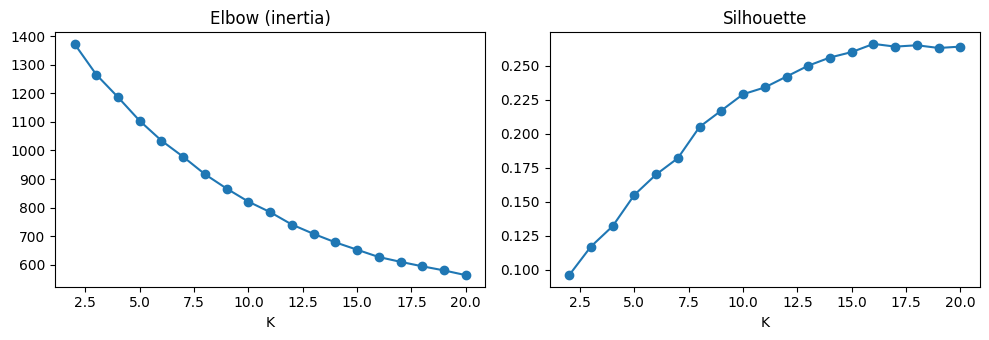

Best K by silhouette (K>=3): 16


In [53]:
rows = []
for K in range(2, 21):
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe)
    rows.append((K, round(km.inertia_, 2), round(silhouette_score(Xe, km.labels_), 3)))
k_tbl = pd.DataFrame(rows, columns=['K', 'inertia', 'silhouette'])
display(k_tbl)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(k_tbl.K, k_tbl.inertia, marker='o');    ax[0].set_title('Elbow (inertia)');  ax[0].set_xlabel('K')
ax[1].plot(k_tbl.K, k_tbl.silhouette, marker='o'); ax[1].set_title('Silhouette');       ax[1].set_xlabel('K')
plt.tight_layout(); plt.show()
print('Best K by silhouette (K>=3):', int(k_tbl[k_tbl.K >= 3].sort_values('silhouette', ascending=False).iloc[0].K))

In [54]:
# K comparison on VALIDATION (full hybrid, discovery mode): this is what decides K
rows = []
for K in [4, 8, 12, 16]:
    parts_k = dict(parts); parts_k['cl'] = make_cluster_pop(K)
    fn = lambda u, p=parts_k: sum(wt * p[name](u) for name, wt in FINAL_W.items())
    rows.append(summarize(evaluate_mode(fn, train_core, uix, val_pairs, mode='discovery'), f'Hybrid K={K}'))
k_val = pd.DataFrame(rows)
display(k_val)
print('Best K by validation NDCG:', k_val.sort_values('ndcg@10', ascending=False).iloc[0]['model'],
      '| K used in the final model:', K_FINAL)
print('K=8 chosen: validation scores of K=4..16 are equal within CI, and K=8 gives interpretable cluster profiles.')
def cluster_profile(K):
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe)
    uid_by_row = np.empty(len(uix), dtype=np.int64)
    for u, i in uix.items():
        uid_by_row[i] = u
    lab_s = pd.Series(km.labels_, index=uid_by_row, name='cluster')
    t = train_core[train_core.user_id.isin(uix)]
    piv = t.pivot_table(index='user_id', columns='event_type', values='product_id', aggfunc='count', fill_value=0)
    for c in ['view', 'cart', 'purchase', 'remove_from_cart']:
        if c not in piv.columns:
            piv[c] = 0
    piv['avg_price'] = t.groupby('user_id')['price'].mean()
    piv = piv.join(lab_s)
    prof = piv.groupby('cluster').agg(users=('view', 'size'), view=('view', 'mean'), cart=('cart', 'mean'),
                                      purchase=('purchase', 'mean'), avg_price=('avg_price', 'mean')).round(2)
    cats = t.merge(lab_s, left_on='user_id', right_index=True)
    share = pd.crosstab(cats['cluster'], cats['main_category'], normalize='index').round(2)
    prof['top_category'] = share.idxmax(axis=1)
    prof['top_cat_share'] = share.max(axis=1)
    return prof
print(f'\nCluster profile (K = {K_FINAL})')
display(cluster_profile(K_FINAL))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,Hybrid K=4,159,0.145,0.094,0.201,0.017,0.027
1,Hybrid K=8,159,0.145,0.094,0.201,0.016,0.027
2,Hybrid K=12,159,0.138,0.088,0.195,0.016,0.026
3,Hybrid K=16,159,0.138,0.088,0.195,0.016,0.027


Best K by validation NDCG: Hybrid K=4 | K used in the final model: 8
Rule: a larger K is only worth it if hit@10 / NDCG improve beyond the confidence intervals; otherwise keep the simpler K.

Cluster profile (K = 8)


,users,view,cart,purchase,avg_price,top_category,top_cat_share
cluster,,,,,,,
0,410,7.19,6.77,1.61,13.52,Beauty & Salon Supplies,0.55
1,173,5.51,5.84,1.29,8.34,Beauty & Salon Supplies,0.66
2,200,9.91,6.35,1.72,6.97,Nail Care,0.67
3,160,10.92,8.26,2.80,3.49,Nail Care,0.55
4,210,7.20,4.66,1.35,13.04,Beauty & Salon Supplies,0.51
5,262,9.36,6.67,1.50,4.66,Beauty & Salon Supplies,0.61
6,221,6.35,6.00,1.48,6.95,Beauty & Salon Supplies,0.46
7,80,8.64,3.00,0.60,13.83,Beauty & Salon Supplies,0.69


### 7.3 Hybrid weights
All 4-way weight combinations (steps of 0.25) are scored on validation. Differences between the top combinations are small (see the two user halves A/B), so the simple **equal weights** are kept and `pop` also protects against weak personal signal.

In [55]:
parts['cl'] = make_cluster_pop(K_FINAL)
users_val = sorted(val_pairs[(val_pairs.source == 'real') & val_pairs.is_warm
                             & val_pairs.user_id.isin(uix)].user_id.unique())
cache = {u: {k: np.asarray(f(u), dtype=float) for k, f in parts.items()} for u in users_val}

keys = ['cf', 'svd', 'cl', 'pop']
grid = [w for w in itertools.product([0, .25, .5, .75, 1], repeat=4) if abs(sum(w) - 1) < 1e-9]

rows = []
for w in grid:
    fn = lambda u, w=w: sum(wk * cache[u][k] for wk, k in zip(w, keys))
    d = evaluate_mode(fn, train_core, uix, val_pairs, mode='discovery')
    r = evaluate_mode(fn, train_core, uix, val_pairs, mode='resurface')
    half = np.arange(len(d)) % 2 == 0                      # two user halves to check stability
    rows.append({**dict(zip(keys, w)),
                 'hit_new': round(d.hit.mean(), 3), 'ndcg_new': round(d.ndcg.mean(), 3),
                 'ndcg_new_A': round(d.ndcg[half].mean(), 3), 'ndcg_new_B': round(d.ndcg[~half].mean(), 3),
                 'hit_old': round(r.hit.mean(), 3), 'ndcg_old': round(r.ndcg.mean(), 3)})
wtbl = pd.DataFrame(rows).sort_values('ndcg_new', ascending=False).reset_index(drop=True)
print('Top 10 weight combinations (new = only new items, old = previously seen items allowed):')
display(wtbl.head(10))
print('Position of equal weights:')
display(wtbl[(wtbl.cf == .25) & (wtbl.svd == .25) & (wtbl.cl == .25) & (wtbl['pop'] == .25)])

Top 10 weight combinations (new = only new items, old = previously seen items allowed):


,cf,svd,cl,pop,hit_new,ndcg_new,ndcg_new_A,ndcg_new_B,hit_old,ndcg_old
0,0.25,0.50,0.25,0.00,0.138,0.030,0.034,0.026,0.553,0.220
1,0.25,0.50,0.00,0.25,0.145,0.030,0.035,0.025,0.547,0.213
2,0.00,0.75,0.25,0.00,0.145,0.030,0.034,0.025,0.509,0.178
3,0.25,0.75,0.00,0.00,0.101,0.028,0.031,0.025,0.553,0.227
4,0.25,0.25,0.25,0.25,0.145,0.027,0.032,0.022,0.553,0.181
5,0.00,1.00,0.00,0.00,0.107,0.027,0.032,0.022,0.491,0.183
6,0.00,0.50,0.50,0.00,0.164,0.027,0.032,0.021,0.472,0.156
7,0.25,0.25,0.50,0.00,0.157,0.027,0.033,0.020,0.579,0.193
8,0.00,0.75,0.00,0.25,0.126,0.026,0.032,0.021,0.497,0.172
9,0.50,0.50,0.00,0.00,0.107,0.026,0.028,0.023,0.585,0.237


Position of equal weights:


,cf,svd,cl,pop,hit_new,ndcg_new,ndcg_new_A,ndcg_new_B,hit_old,ndcg_old
4,0.25,0.25,0.25,0.25,0.145,0.027,0.032,0.022,0.553,0.181


### 7.4 Cold-start users (no history)
New users cannot be served by personal models, so a global ranking is used. Candidates are compared on validation.

In [56]:
def cold_candidates(train_df, pop7, m=20):
    """Global rankings for users without history. conv = smoothed purchase probability per product."""
    d_old = train_df[train_df.user_id < SYN_MIN]
    cnt = (d_old.pivot_table(index='product_id', columns='event_type', values='user_id',
                             aggfunc='count', fill_value=0).reindex(item_ids).fillna(0))
    for c in ['view', 'cart', 'purchase']:
        if c not in cnt.columns:
            cnt[c] = 0
    views = (cnt['view'] + cnt['cart']).values.astype(float)
    buys  = cnt['purchase'].values.astype(float)
    p0   = buys.sum() / (views.sum() + 1e-9)
    conv = (buys + m * p0) / (views + m)
    nz = lambda x: x / (np.max(x) + 1e-9)
    return {'Popularity (7d)':                    pop7,
            'Most purchased by old users':        buys,
            'Purchase probability (smoothed)':    conv,
            'Popularity x purchase probability':  nz(pop7) * nz(conv),
            'Popularity + purchase prob (50/50)': 0.5 * nz(pop7) + 0.5 * nz(conv)}

cands = {'Random': np.random.default_rng(42).random(len(item_ids)),
         **cold_candidates(train_core, pop_core_7_real)}
rows = [summarize(evaluate_cold(v, val_pairs), name) for name, v in cands.items()]
cold = pd.DataFrame(rows)
display(cold.sort_values('ndcg@10', ascending=False).reset_index(drop=True))

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,Popularity x purchase probability,162,0.241,0.179,0.309,0.029,0.058
1,Popularity (7d),162,0.210,0.148,0.272,0.026,0.055
2,Most purchased by old users,162,0.191,0.130,0.253,0.024,0.050
3,Popularity + purchase prob (50/50),162,0.167,0.111,0.228,0.020,0.043
4,Random,162,0.019,0.000,0.043,0.002,0.003
5,Purchase probability (smoothed),162,0.031,0.006,0.062,0.003,0.003


## 8. Final test (run once)
Settings are frozen: K=8, equal weights, n_svd=50, trained on **real users before 20 Dec**, tested on purchases from 20 Dec onwards. No tuning happens after this point.

In [57]:
def build_parts(train_df, Rm, uix, pop_vec, n_svd=50, K=K_FINAL, lam=0.3):
    """Fit CF / SVD / cluster / popularity components on any training data."""
    pn = pop_vec / (pop_vec.max() + 1e-9)
    tie_ = 1e-6 * pn
    S = cosine_similarity(Rm.T, dense_output=False).toarray(); np.fill_diagonal(S, 0)
    cf = lambda u: np.asarray(Rm[uix[u]] @ S).ravel() + tie_
    m = TruncatedSVD(n_components=n_svd, random_state=42)
    U = m.fit_transform(Rm); V = m.components_
    svd = lambda u: U[uix[u]] @ V + tie_
    Xe_ = normalize(TruncatedSVD(n_components=16, random_state=42).fit_transform(Rm))
    lab = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe_).labels_
    tr_ = train_df[train_df.user_id.isin(uix)]
    w = tr_.event_type.map(W_POP).values
    ip = tr_.product_id.map(i_idx).values.astype(int)
    uc = lab[tr_.user_id.map(uix).values.astype(int)]
    cp = {}
    for c in range(K):
        v = np.bincount(ip[uc == c], weights=w[uc == c], minlength=len(item_ids))
        cp[c] = v / (v.max() + 1e-9)
    cl = lambda u: (1 - lam) * cp[lab[uix[u]]] + lam * pn
    return {'cf': nrm(cf), 'svd': nrm(svd), 'cl': cl, 'pop': (lambda u: pn)}, cf, svd

Rt, _, uixt = build_R(train_t, real_only=True)
pop_t = popularity_scores(train_t, days=7, real_only=True)
parts_t, cf_raw, svd_raw = build_parts(train_t, Rt, uixt, pop_t)
final_fn = lambda u: sum(w * parts_t[k](u) for k, w in FINAL_W.items())

models_t = {'Popularity (7d, real)': parts_t['pop'], 'CF': cf_raw, 'SVD n=50': svd_raw, 'FINAL hybrid': final_fn}
rows, disc_res = [], {}
for name, fn in models_t.items():
    a = summarize(evaluate_mode(fn, train_t, uixt, test_t, mode='resurface'), name)
    disc_res[name] = evaluate_mode(fn, train_t, uixt, test_t, mode='discovery')
    b = summarize(disc_res[name], name)
    rows.append((name, b['users'], a['hit@10'], b['hit@10'], b['ci_lo'], b['ci_hi'], b['ndcg@10']))
final_tbl = pd.DataFrame(rows, columns=['model', 'users', 'hit_resurface', 'hit_DISCOVERY',
                                        'disc_ci_lo', 'disc_ci_hi', 'ndcg_DISCOVERY'])
display(final_tbl)

warm_diffs = {}
for col in ['hit', 'ndcg']:
    d_, lo, hi = paired_diff(disc_res['FINAL hybrid'], disc_res['Popularity (7d, real)'], col)
    warm_diffs[col] = [d_, lo, hi]
    print(f'FINAL - Popularity ({col}, new items): {d_} [{lo}, {hi}] -> {verdict(lo, hi)}')

,model,users,hit_resurface,hit_DISCOVERY,disc_ci_lo,disc_ci_hi,ndcg_DISCOVERY
0,"Popularity (7d, real)",161,0.236,0.161,0.106,0.217,0.040
1,CF,161,0.416,0.124,0.075,0.174,0.036
2,SVD n=50,161,0.429,0.112,0.068,0.161,0.020
3,FINAL hybrid,161,0.453,0.199,0.137,0.261,0.052


FINAL - Popularity (hit, new items): 0.037 [-0.025, 0.093] -> not significant (CI includes 0)
FINAL - Popularity (ndcg, new items): 0.013 [-0.004, 0.031] -> not significant (CI includes 0)


In [58]:
# cold-start final test (users with no history before 20 Dec)
cold_t = cold_candidates(train_t, pop_t)
cold_final = pd.DataFrame([summarize(evaluate_cold(cold_t[n], test_t), n)
                           for n in ['Popularity (7d)', 'Popularity x purchase probability']])
display(cold_final)

,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,Popularity (7d),234,0.209,0.158,0.261,0.025,0.048
1,Popularity x purchase probability,234,0.188,0.137,0.239,0.023,0.039


## 9. Robustness checks (rolling backtests)
Extra evidence on more time windows. **Fixed:** every evaluation window now ends before the 20 Dec test cutoff, so the final test period is never reused.
Note: K and weights were tuned on 13-19 Dec, which overlaps some windows, so this is a sanity check and **not** independent proof.

In [67]:
# SVD n=200 vs SVD n=50 vs hybrid vs popularity (all windows end before the test period)
HORIZON = pd.Timedelta(days=7)
WINDOWS3 = ['2019-12-06', '2019-12-09', '2019-12-12', '2019-12-16']
long_rows = []
def svd_fn(Rm, uix, pop_vec, n):
    pn_ = pop_vec / (pop_vec.max() + 1e-9)
    tie_ = 1e-6 * pn_
    m = TruncatedSVD(n_components=n, random_state=42)
    U = m.fit_transform(Rm); V = m.components_
    return lambda u: U[uix[u]] @ V + tie_

for c in WINDOWS3:
    cut = pd.Timestamp(c, tz='UTC')
    end = min(cut + HORIZON, CUTOFF)
    tr_w = df[df.event_time < cut]
    lat  = df[(df.event_time >= cut) & (df.event_time < end)]
    pairs = make_pairs(tr_w, lat)

    Rw, _, uixw = build_R(tr_w, real_only=True)
    pop_w = popularity_scores(tr_w, days=7, real_only=True)
    parts_w, _, svd50_w = build_parts(tr_w, Rw, uixw, pop_w)
    models_w = {
        'Popularity (7d)': parts_w['pop'],
        'SVD n=50':        svd50_w,
        'SVD n=200':       svd_fn(Rw, uixw, pop_w, 200),
        'Hybrid (FINAL)':  (lambda u, pw=parts_w: sum(w * pw[k](u) for k, w in FINAL_W.items())),
    }
    n_users = 0
    for mode in ['resurface', 'discovery']:
        for name, fn in models_w.items():
            r = evaluate_mode(fn, tr_w, uixw, pairs, mode=mode)
            n_users = len(r)
            r['window'], r['mode'], r['model'] = c, mode, name
            long_rows.append(r)
    print(c, '| eval:', cut.date(), '->', (end - pd.Timedelta(days=1)).date(), '| users:', n_users)

L3 = pd.concat(long_rows, ignore_index=True)
rng3 = np.random.default_rng(42)
out = []
for mode in ['resurface', 'discovery']:
    pu = L3[L3['mode'] == mode].groupby(['model', 'user_id'])[['hit', 'ndcg']].mean()
    print('\nMODE:', mode)
    display(pu.groupby('model').agg(users=('hit', 'size'), hit=('hit', 'mean'), ndcg=('ndcg', 'mean')).round(3))
    for a_, b_ in [('SVD n=200', 'Popularity (7d)'), ('SVD n=200', 'Hybrid (FINAL)'), ('Hybrid (FINAL)', 'Popularity (7d)')]:
        A, B = pu.loc[a_], pu.loc[b_]
        idx = A.index.intersection(B.index)
        for col in ['hit', 'ndcg']:
            d_ = (A.loc[idx, col] - B.loc[idx, col]).values
            means = rng3.choice(d_, (2000, len(d_))).mean(axis=1)
            lo, hi = np.percentile(means, [2.5, 97.5])
            out.append((mode, f'{a_} - {b_}', col, len(d_), round(d_.mean(), 3), round(lo, 3), round(hi, 3), verdict(lo, hi)))
display(pd.DataFrame(out, columns=['mode', 'comparison', 'metric', 'users', 'diff', 'ci_lo', 'ci_hi', 'result']))

2019-12-06 | eval: 2019-12-06 -> 2019-12-12 | users: 99
2019-12-09 | eval: 2019-12-09 -> 2019-12-15 | users: 138
2019-12-12 | eval: 2019-12-12 -> 2019-12-18 | users: 157
2019-12-16 | eval: 2019-12-16 -> 2019-12-19 | users: 116

MODE: resurface


,users,hit,ndcg
model,,,
Hybrid (FINAL),301,0.556,0.207
Popularity (7d),301,0.231,0.052
SVD n=200,301,0.648,0.318
SVD n=50,301,0.531,0.206



MODE: discovery


,users,hit,ndcg
model,,,
Hybrid (FINAL),301,0.152,0.032
Popularity (7d),301,0.130,0.021
SVD n=200,301,0.091,0.020
SVD n=50,301,0.102,0.027


,mode,comparison,metric,users,diff,ci_lo,ci_hi,result
0,resurface,SVD n=200 - Popularity (7d),hit,301,0.417,0.354,0.478,real difference
1,resurface,SVD n=200 - Popularity (7d),ndcg,301,0.266,0.232,0.302,real difference
2,resurface,SVD n=200 - Hybrid (FINAL),hit,301,0.092,0.055,0.130,real difference
3,resurface,SVD n=200 - Hybrid (FINAL),ndcg,301,0.111,0.086,0.136,real difference
4,resurface,Hybrid (FINAL) - Popularity (7d),hit,301,0.325,0.264,0.383,real difference
5,resurface,Hybrid (FINAL) - Popularity (7d),ndcg,301,0.155,0.132,0.179,real difference
6,discovery,SVD n=200 - Popularity (7d),hit,301,-0.039,-0.084,0.007,not significant (CI includes 0)
7,discovery,SVD n=200 - Popularity (7d),ndcg,301,-0.002,-0.013,0.011,not significant (CI includes 0)
8,discovery,SVD n=200 - Hybrid (FINAL),hit,301,-0.061,-0.098,-0.029,real difference
9,discovery,SVD n=200 - Hybrid (FINAL),ndcg,301,-0.012,-0.022,-0.002,real difference


In [68]:
# ===== BT-FIX: metrics ke liye wahi backtest jo cell 40 mein hai (4 windows) =====
pu = L3[L3['mode'] == 'discovery'].groupby(['model', 'user_id'])[['hit', 'ndcg']].mean()
H4, P4 = pu.loc['Hybrid (FINAL)'], pu.loc['Popularity (7d)']
rng_f = np.random.default_rng(42)
bt = {}
for col, key in [('hit', 'd_hit'), ('ndcg', 'd_ndcg')]:
    v = (H4[col] - P4[col]).values
    means = rng_f.choice(v, (2000, len(v))).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    bt[key] = [round(float(v.mean()), 3), round(float(lo), 3), round(float(hi), 3)]
    print(f'Hybrid - Popularity {key}: {bt[key]} (users: {len(v)}) -> {verdict(lo, hi)}')
per_user = H4

Hybrid - Popularity d_hit: [0.022, -0.017, 0.063] (users: 301) -> not significant (CI includes 0)
Hybrid - Popularity d_ndcg: [0.011, 0.002, 0.021] (users: 301) -> real difference


In [69]:
tr_syn = train_core[train_core.user_id >= SYN_MIN]
R_syn_core, _, uix_syn_core = build_R(tr_syn)
pop_syn_core = popularity_scores(tr_syn, days=7)
print('Synthetic users in train_core matrix:', R_syn_core.shape)

parts_s, cf_s, svd_s = build_parts(tr_syn, R_syn_core, uix_syn_core, pop_syn_core)
hyb_s = lambda u: sum(w * parts_s[k](u) for k, w in FINAL_W.items())

models_s = {
    'Popularity (synthetic, 7d)':            parts_s['pop'],
    'Popularity (REAL, 7d) [wrong segment]': (lambda u: pop_core_7_real),
    'CF':                                    cf_s,
    'SVD n=50':                              svd_s,
    'Hybrid (synthetic)':                    hyb_s,
}
rows = []
for name, fn in models_s.items():
    for mode in ['resurface', 'discovery']:
        r = evaluate_mode(fn, train_core, uix_syn_core, val_pairs, mode=mode, source='synthetic')
        s = summarize(r, name)
        rows.append({'model': name, 'mode': mode, 'users': s['users'], 'hit@10': s['hit@10'],
                     'ci_lo': s['ci_lo'], 'ci_hi': s['ci_hi'], 'ndcg@10': s['ndcg@10']})
display(pd.DataFrame(rows).sort_values(['mode', 'ndcg@10'], ascending=[True, False]).reset_index(drop=True))

Synthetic users in train_core matrix: (793, 1885)


,model,mode,users,hit@10,ci_lo,ci_hi,ndcg@10
0,Hybrid (synthetic),discovery,287,0.310,0.254,0.366,0.148
1,CF,discovery,287,0.258,0.209,0.310,0.122
2,"Popularity (synthetic, 7d)",discovery,287,0.244,0.192,0.296,0.105
3,SVD n=50,discovery,287,0.101,0.066,0.136,0.046
4,"Popularity (REAL, 7d) [wrong segment]",discovery,287,0.000,0.000,0.000,0.000
5,Hybrid (synthetic),resurface,287,0.362,0.303,0.418,0.175
6,CF,resurface,287,0.317,0.261,0.369,0.137
7,"Popularity (synthetic, 7d)",resurface,287,0.310,0.258,0.362,0.130
8,SVD n=50,resurface,287,0.213,0.164,0.261,0.099
9,"Popularity (REAL, 7d) [wrong segment]",resurface,287,0.000,0.000,0.000,0.000


## 11. Final model, recommendations and export
The **deployed** model is fitted on all real users and all dates (so it also learns from the test period). The reported metrics above come from the model trained before 20 Dec. The saved model is checked to give the same top-10 as the tested code path.

In [70]:
def _nrm(x):
    s = np.clip(np.asarray(x, dtype=float), 0, None)
    return s / (s.max() + 1e-9)

def fit_final_model(train_df, Rm, uix, pop_vec, weights, n_svd=50, K=K_FINAL, lam=0.3):
    """Same maths as build_parts, but keeps the fitted objects so they can be saved."""
    pn = pop_vec / (pop_vec.max() + 1e-9)
    S = cosine_similarity(Rm.T, dense_output=False).toarray()
    np.fill_diagonal(S, 0)
    svd_model = TruncatedSVD(n_components=n_svd, random_state=42)
    U = svd_model.fit_transform(Rm)
    emb_model = TruncatedSVD(n_components=16, random_state=42)
    Xe_ = normalize(emb_model.fit_transform(Rm))
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xe_)
    lab = km.labels_
    tr_ = train_df[train_df.user_id.isin(uix)]
    w = tr_.event_type.map(W_POP).values
    ip = tr_.product_id.map(i_idx).values.astype(int)
    uc = lab[tr_.user_id.map(uix).values.astype(int)]
    cp = {}
    for c in range(K):
        v = np.bincount(ip[uc == c], weights=w[uc == c], minlength=len(item_ids))
        cp[c] = v / (v.max() + 1e-9)
    return {'R': Rm, 'S': S, 'U': U, 'V': svd_model.components_, 'lab': lab, 'cp': cp,
            'pn': pn, 'uix': uix, 'item_ids': item_ids, 'weights': weights, 'lam': lam,
            'svd_model': svd_model, 'emb_model': emb_model, 'kmeans': km}

def model_scores(M, u):
    """Score every product for user u using only the saved model (no retraining)."""
    i = M['uix'][u]
    tie_ = 1e-6 * M['pn']
    cf  = _nrm(np.asarray(M['R'][i] @ M['S']).ravel() + tie_)
    svd = _nrm(M['U'][i] @ M['V'] + tie_)
    cl  = (1 - M['lam']) * M['cp'][M['lab'][i]] + M['lam'] * M['pn']
    w = M['weights']
    return w['cf'] * cf + w['svd'] * svd + w['cl'] * cl + w['pop'] * M['pn']

# real-user model (same setting as validation / test / backtest)
R_srv, _, uix_srv = build_R(df, real_only=True)
pop_srv = popularity_scores(df, days=7, real_only=True)
M_srv = fit_final_model(df, R_srv, uix_srv, pop_srv, FINAL_W)
joblib.dump(M_srv, f'{OUT}/hybrid_model.joblib', compress=3)
print('Saved:', f'{OUT}/hybrid_model.joblib', '| size MB:', round(os.path.getsize(f'{OUT}/hybrid_model.joblib') / 1e6, 1))

# check: loaded model == tested code path
M_load = joblib.load(f'{OUT}/hybrid_model.joblib')
parts_chk, _, _ = build_parts(df, R_srv, uix_srv, pop_srv)
chk_fn = lambda u: sum(w * parts_chk[k](u) for k, w in FINAL_W.items())
sample = list(uix_srv)[:50]
same = sum(set(topk(model_scores(M_load, u), 10)) == set(topk(np.asarray(chk_fn(u), dtype=float), 10)) for u in sample)
print(f'Saved model == tested code path: {same}/{len(sample)} users have identical top-10')
assert same == len(sample), 'saved model differs from tested model'

Saved: /kaggle/working/dashboard_export/hybrid_model.joblib | size MB: 6.7
Saved model == tested code path: 50/50 users have identical top-10


In [71]:
prod_info = products.set_index('product_id')[['product_name', 'brand', 'main_category', 'price_pkr']]

def recommend(user_id, k=10, only_new=True, model=None):
    """Known user -> hybrid. Unknown user -> popularity (last 7 days)."""
    M = M_srv if model is None else model
    if user_id in M['uix']:
        s = model_scores(M, user_id).copy()
        t = df[df.user_id == user_id]
        seen = t['product_id'] if only_new else t[t.event_type == 'purchase']['product_id']
        s[seen.map(i_idx).values] = -np.inf
        kind = 'hybrid (existing user)'
    else:
        s = M['pn'].copy()
        kind = 'popularity (new user)'
    ids = item_ids[topk(s, k)]
    out = prod_info.loc[ids].reset_index()
    out.insert(0, 'rank', range(1, k + 1))
    print('Model:', kind, '| user:', user_id)
    return out

display(recommend(list(uix_srv)[0]))
display(recommend(123456789))

# top-10 for every real user (history: only purchases removed, discovery: everything seen removed)
g_all = df.groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
g_buy = df[df.event_type == 'purchase'].groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
empty = np.array([], dtype=int)

rows = []
for u in uix_srv:
    base = model_scores(M_srv, u)
    for mode, seen in (('history', g_buy.get(u, empty)), ('discovery', g_all.get(u, empty))):
        s = base.copy(); s[seen] = -np.inf
        for rank, ix in enumerate(topk(s, 10), start=1):
            rows.append((u, mode, rank, int(item_ids[ix]), float(base[ix])))
rec_real = pd.DataFrame(rows, columns=['user_id', 'mode', 'rank', 'product_id', 'score'])
rec_real.to_csv(f'{OUT}/recommendations_top10.csv', index=False)

# new users: popularity (it beat "popularity x purchase probability" on the final test)
pop_top = topk(M_srv['pn'], 10)
pd.DataFrame({'rank': range(1, 11), 'product_id': item_ids[pop_top].astype(int),
              'score': M_srv['pn'][pop_top]}).to_csv(f'{OUT}/cold_start_top10.csv', index=False)
final_tbl.to_csv(f'{OUT}/test_results_warm.csv', index=False)

# metrics: all numbers come from variables computed above, nothing typed by hand
cold_test = cold_final[cold_final.model == 'Popularity (7d)'].iloc[0]
metrics = {
    'final_model': f'Hybrid: CF 0.25 + SVD(n=50) 0.25 + KMeans clusters(K={K_FINAL}) 0.25 + Popularity(7d) 0.25; trained on real users only',
    'split': 'train < 2019-12-20 | test >= 2019-12-20 | validation 13-19 Dec (inside train)',
    'warm_test_final_new_items': {
        'table': json.loads(final_tbl.to_json(orient='records')),
        'hybrid_minus_popularity': {c: {'diff': v[0], 'ci': [v[1], v[2]], 'result': verdict(v[1], v[2])}
                                    for c, v in warm_diffs.items()},
    },
    'cold_start_test': {'model': 'Popularity (7d)', 'users': int(cold_test['users']),
                        'hit@10': float(cold_test['hit@10']),
                        'ci': [float(cold_test['ci_lo']), float(cold_test['ci_hi'])]},
    'rolling_backtest_one_row_per_user': {
        'note': 'windows end before 20 Dec; K/weights tuned on overlapping dates, so not fully independent',
        'users': int(len(per_user)),
        'hit_diff_vs_popularity': bt['d_hit'], 'ndcg_diff_vs_popularity': bt['d_ndcg']},
}
json.dump(metrics, open(f'{OUT}/metrics.json', 'w'), indent=2)
print(sorted(os.listdir(OUT)))

Model: hybrid (existing user) | user: 51824526


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,5809910,Grattol Nail Product #9910,grattol,Nail Care,1467
1,2,5833335,Bpw.Style Nail Product #3335,bpw.style,Nail Care,445
2,3,5815662,Generic Beauty Product #5662,unknown,Beauty & Salon Supplies,258
3,4,5833325,Bpw.Style Nail Product #3325,bpw.style,Nail Care,445
4,5,5833326,Bpw.Style Nail Product #3326,bpw.style,Nail Care,445
5,6,5906119,Bpw.Style Nail Product #6119,bpw.style,Nail Care,356
6,7,5700037,Runail Nail Product #0037,runail,Nail Care,112
7,8,5833334,Bpw.Style Nail Product #3334,bpw.style,Nail Care,221
8,9,5854897,Irisk Nail Product #4897,irisk,Nail Care,90
9,10,5802432,Generic Beauty Product #2432,unknown,Beauty & Salon Supplies,90


Model: popularity (new user) | user: 123456789


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,5809910,Grattol Nail Product #9910,grattol,Nail Care,1467
1,2,5809912,Grattol Nail Product #9912,grattol,Nail Care,1467
2,3,5815662,Generic Beauty Product #5662,unknown,Beauty & Salon Supplies,258
3,4,5802432,Generic Beauty Product #2432,unknown,Beauty & Salon Supplies,90
4,5,5561044,Generic Beauty Product #1044,unknown,Beauty & Salon Supplies,840
5,6,5854897,Irisk Nail Product #4897,irisk,Nail Care,90
6,7,5751422,UNO Nail Product #1422,uno,Nail Care,3066
7,8,5700037,Runail Nail Product #0037,runail,Nail Care,112
8,9,5809911,Grattol Nail Product #9911,grattol,Nail Care,1467
9,10,5686925,Generic Beauty Product #6925,unknown,Beauty & Salon Supplies,98


['cold_start_top10.csv', 'cold_start_top10_synthetic.csv', 'hybrid_model.joblib', 'hybrid_model_synthetic.joblib', 'metrics.json', 'products.csv', 'recommendations_top10.csv', 'recommendations_top10_all.csv', 'test_results_warm.csv']


In [72]:
# synthetic-segment model + combined export (DEMO ONLY)
df_syn = df[df.user_id >= SYN_MIN]
R_syn, _, uix_syn = build_R(df_syn)
pop_syn = popularity_scores(df_syn, days=7)
M_syn = fit_final_model(df_syn, R_syn, uix_syn, pop_syn, FINAL_W)
joblib.dump(M_syn, f'{OUT}/hybrid_model_synthetic.joblib', compress=3)
print('Saved synthetic model | users:', R_syn.shape[0], '| size MB:',
      round(os.path.getsize(f'{OUT}/hybrid_model_synthetic.joblib') / 1e6, 1))

def recommend_any(user_id, k=10, only_new=True, segment=None):
    """Chooses the right model from the user id (or the segment argument for new users)."""
    is_syn = (user_id >= SYN_MIN) if segment is None else (segment == 'synthetic')
    return recommend(user_id, k=k, only_new=only_new, model=M_syn if is_syn else M_srv)

display(recommend_any(list(uix_srv)[0]))                  # real user
display(recommend_any(list(uix_syn)[0]))                  # synthetic user
display(recommend_any(123456789, segment='synthetic'))    # new synthetic user

g_all_s = df_syn.groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
g_buy_s = df_syn[df_syn.event_type == 'purchase'].groupby('user_id')['product_id'].apply(lambda s: s.map(i_idx).values)
rows_s = []
for u in uix_syn:
    base = model_scores(M_syn, u)
    for mode, seen in (('history', g_buy_s.get(u, empty)), ('discovery', g_all_s.get(u, empty))):
        s = base.copy(); s[seen] = -np.inf
        for rank, ix in enumerate(topk(s, 10), start=1):
            rows_s.append((u, mode, rank, int(item_ids[ix]), float(base[ix])))
rec_syn = pd.DataFrame(rows_s, columns=['user_id', 'mode', 'rank', 'product_id', 'score'])
rec_syn['segment'] = 'synthetic'
rec_real_seg = rec_real.copy(); rec_real_seg['segment'] = 'real'
pd.concat([rec_real_seg, rec_syn], ignore_index=True).to_csv(f'{OUT}/recommendations_top10_all.csv', index=False)

pop_top_s = topk(M_syn['pn'], 10)
pd.DataFrame({'rank': range(1, 11), 'product_id': item_ids[pop_top_s].astype(int),
              'score': M_syn['pn'][pop_top_s]}).to_csv(f'{OUT}/cold_start_top10_synthetic.csv', index=False)

# synthetic validation numbers go into metrics.json with a clear label
r_syn = evaluate_mode(hyb_s, train_core, uix_syn_core, val_pairs, mode='discovery', source='synthetic')
s_syn = summarize(r_syn, 'Hybrid (synthetic)')
metrics['synthetic_segment_validation'] = {
    'note': 'DEMO ONLY: validation on synthetic data, not a claim about real performance.',
    'users': int(s_syn['users']), 'hit@10_new_items': float(s_syn['hit@10']),
    'ci': [float(s_syn['ci_lo']), float(s_syn['ci_hi'])],
    'model': 'Hybrid trained on synthetic users only (separate joblib)'}
json.dump(metrics, open(f'{OUT}/metrics.json', 'w'), indent=2)

# the saved synthetic model must reproduce the in-memory one
M_chk = joblib.load(f'{OUT}/hybrid_model_synthetic.joblib')
sample = list(uix_syn)[:50]
same = sum(set(topk(model_scores(M_chk, u), 10)) == set(topk(model_scores(M_syn, u), 10)) for u in sample)
print(f'Saved synthetic model check: {same}/{len(sample)} users have identical top-10')
assert same == len(sample)

products[['product_id', 'product_name', 'brand', 'main_category', 'price_pkr']].to_csv(f'{OUT}/products.csv', index=False)
print(sorted(os.listdir(OUT)))

Saved synthetic model | users: 800 | size MB: 1.9
Model: hybrid (existing user) | user: 51824526


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,5809910,Grattol Nail Product #9910,grattol,Nail Care,1467
1,2,5833335,Bpw.Style Nail Product #3335,bpw.style,Nail Care,445
2,3,5815662,Generic Beauty Product #5662,unknown,Beauty & Salon Supplies,258
3,4,5833325,Bpw.Style Nail Product #3325,bpw.style,Nail Care,445
4,5,5833326,Bpw.Style Nail Product #3326,bpw.style,Nail Care,445
5,6,5906119,Bpw.Style Nail Product #6119,bpw.style,Nail Care,356
6,7,5700037,Runail Nail Product #0037,runail,Nail Care,112
7,8,5833334,Bpw.Style Nail Product #3334,bpw.style,Nail Care,221
8,9,5854897,Irisk Nail Product #4897,irisk,Nail Care,90
9,10,5802432,Generic Beauty Product #2432,unknown,Beauty & Salon Supplies,90


Model: hybrid (existing user) | user: 990000001


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,9000040,SG Sports T-Shirt,sg,Sports,4561
1,2,9000002,Yonex Tennis Racket,yonex,Sports,16870
2,3,9000001,Reebok Running Shoes,reebok,Sports,32376
3,4,9000050,Yonex Football,yonex,Sports,5113
4,5,9000152,H&M Handbag,h&m,Fashion,33474
5,6,9000045,Puma Running Shoes,puma,Sports,24786
6,7,9000020,Yonex Sports Water Bottle,yonex,Sports,1784
7,8,9000200,Lock&Lock Electric Kettle,lock&lock,Home & Kitchen,5790
8,9,9000011,Nike Cricket Bat,nike,Sports,30061
9,10,9000100,Oppo Tablet,oppo,Electronics,45853


Model: popularity (new user) | user: 123456789


,rank,product_id,product_name,brand,main_category,price_pkr
0,1,9000005,Nike Training Jacket,nike,Sports,16324
1,2,9000110,Logitech Tablet,logitech,Electronics,107884
2,3,9000152,H&M Handbag,h&m,Fashion,33474
3,4,9000040,SG Sports T-Shirt,sg,Sports,4561
4,5,9000030,Reebok Gym Gloves,reebok,Sports,3808
5,6,9000200,Lock&Lock Electric Kettle,lock&lock,Home & Kitchen,5790
6,7,9000146,Aldo Hoodie,aldo,Fashion,11886
7,8,9000100,Oppo Tablet,oppo,Electronics,45853
8,9,9000002,Yonex Tennis Racket,yonex,Sports,16870
9,10,9000188,Pyrex Blender,pyrex,Home & Kitchen,20874


Saved synthetic model check: 50/50 users have identical top-10
['cold_start_top10.csv', 'cold_start_top10_synthetic.csv', 'hybrid_model.joblib', 'hybrid_model_synthetic.joblib', 'metrics.json', 'products.csv', 'recommendations_top10.csv', 'recommendations_top10_all.csv', 'test_results_warm.csv']


## 12. Results summary

In [73]:
print('=== WARM users, NEW items (discovery), final test, real users only ===')
display(final_tbl)
for c, v in warm_diffs.items():
    print(f'FINAL hybrid - Popularity {c}: {v[0]} [{v[1]}, {v[2]}] -> {verdict(v[1], v[2])}')
print('\n=== COLD-START users, final test ===')
display(cold_final)
print('\n=== Rolling backtest (windows end before test period) ===')
for c, v in bt.items():
    print(f'Hybrid - Popularity {c}: {v[0]} [{v[1]}, {v[2]}] -> {verdict(v[1], v[2])}')

=== WARM users, NEW items (discovery), final test, real users only ===


,model,users,hit_resurface,hit_DISCOVERY,disc_ci_lo,disc_ci_hi,ndcg_DISCOVERY
0,"Popularity (7d, real)",161,0.236,0.161,0.106,0.217,0.040
1,CF,161,0.416,0.124,0.075,0.174,0.036
2,SVD n=50,161,0.429,0.112,0.068,0.161,0.020
3,FINAL hybrid,161,0.453,0.199,0.137,0.261,0.052


FINAL hybrid - Popularity hit: 0.037 [-0.025, 0.093] -> not significant (CI includes 0)
FINAL hybrid - Popularity ndcg: 0.013 [-0.004, 0.031] -> not significant (CI includes 0)

=== COLD-START users, final test ===


,model,users,hit@10,ci_lo,ci_hi,precision@10,ndcg@10
0,Popularity (7d),234,0.209,0.158,0.261,0.025,0.048
1,Popularity x purchase probability,234,0.188,0.137,0.239,0.023,0.039



=== Rolling backtest (windows end before test period) ===
Hybrid - Popularity d_hit: 0.022 [-0.017, 0.063] -> not significant (CI includes 0)
Hybrid - Popularity d_ndcg: 0.011 [0.002, 0.021] -> real difference


**How to read the results honestly**
- The hybrid is compared against a strong baseline (popularity of the last 7 days). Check the final-test confidence interval above: if it includes 0, the improvement on the test set is **not statistically proven** (only ~160 test users).
- Absolute hit@10 on *new* items is low (roughly 0.1-0.2) - expected for a one-month, sparse dataset.
- The 20 Dec - 1 Jan test window contains the holiday season, so behaviour may differ from normal weeks.
- Synthetic-segment results are demo-only.

**Known limitations:** purchase and view+cart get the same implicit rating (cap = 2); `remove_from_cart` is ignored rather than treated as negative feedback; K-means clusters are only loosely separated (silhouette ~0.2); product names are anonymised.